# 02. Asian, barrier, American options, the time step and Greeks

## 1. Objective
Understand how path dependence, monitoring frequency, early exercise and bumping affect prices and sensitivities.

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 30)

## 2. Asian options
Arithmetic average with a geometric control variate; geometric average validated against its exact formula.

In [2]:
pd.read_csv('../outputs/tables/04_asian_vs_european.csv').round(4)

,sigma,european,asian_arithmetic,se_arith,asian_geometric,geometric_closed_form,asian_over_european
0,0.1,3.3523,1.8633,0.0000,1.8397,1.8428,0.5558
1,0.2,5.6607,3.2110,0.0002,3.1329,3.1407,0.5672
2,0.3,7.9996,4.5726,0.0004,4.4092,4.4217,0.5716
3,0.4,10.3408,5.9359,0.0007,5.6559,5.6733,0.5740


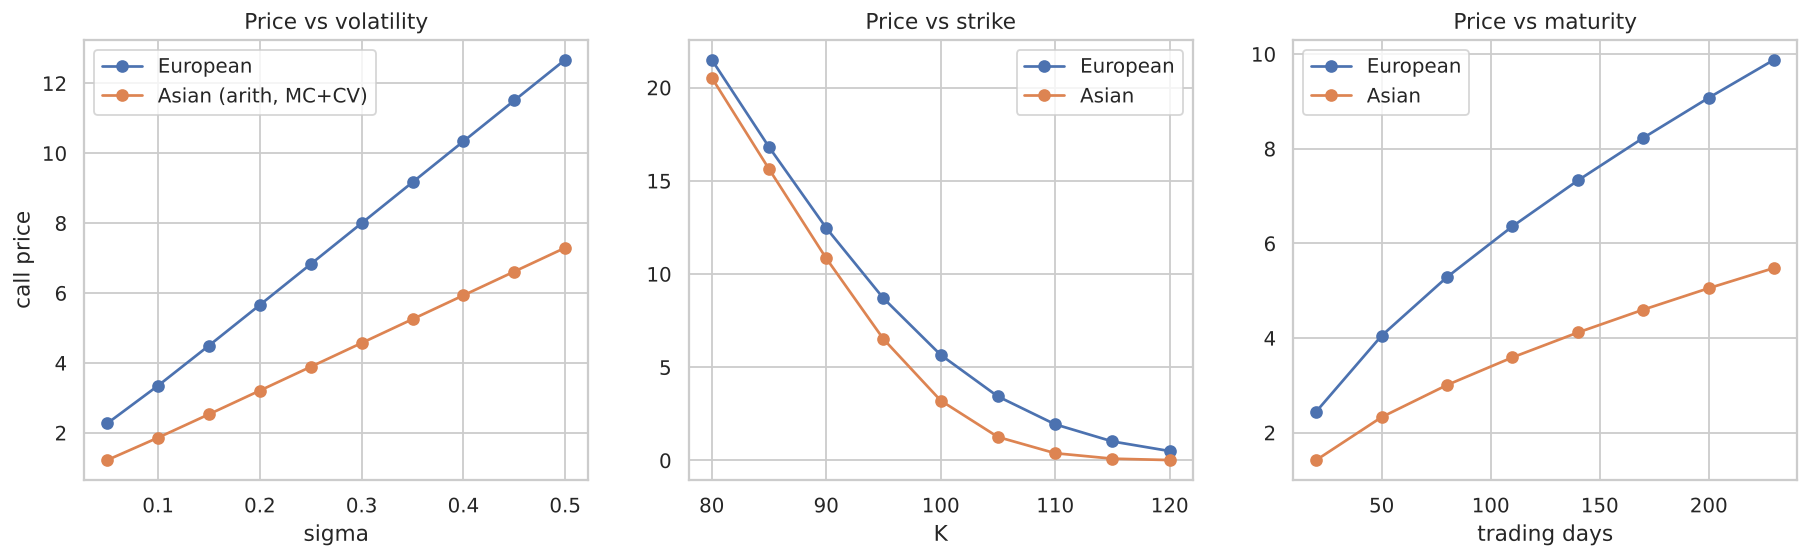

In [3]:
display(Image('../outputs/figures/04_asian_vs_european.png'))

Asian options are about 56-57% of the European price: averaging reduces effective volatility. The arithmetic average is always above the geometric one (AM-GM).

## 3. Barrier options (8 types)

In [4]:
pd.read_csv('../outputs/tables/05_barrier_all_types.csv').round(4)

,type,barrier_type,H,mc_discrete,se,closed_form_continuous,closed_form_bgk,vanilla,z_vs_bgk
0,call,up-and-in,115,4.0195,0.0114,4.2205,4.0139,5.6607,0.4945
1,call,up-and-out,115,1.6361,0.0044,1.4403,1.6469,5.6607,-2.4571
2,call,down-and-in,85,0.0081,0.0004,0.0127,0.0084,5.6607,-0.7328
3,call,down-and-out,85,5.6475,0.0091,5.6481,5.6524,5.6607,-0.5369
4,put,up-and-in,115,0.0238,0.0006,0.0349,0.0242,3.8909,-0.5231
5,put,up-and-out,115,3.8637,0.0070,3.8560,3.8667,3.8909,-0.4288
6,put,down-and-in,85,2.0270,0.0081,2.1894,2.0278,3.8909,-0.1010
7,put,down-and-out,85,1.8605,0.0045,1.7014,1.8631,3.8909,-0.5598


The Monte Carlo price (discrete monitoring) matches the BGK-corrected formula within about 1 cent but differs from the *continuous* formula by up to 20 cents: a real effect, not an error.

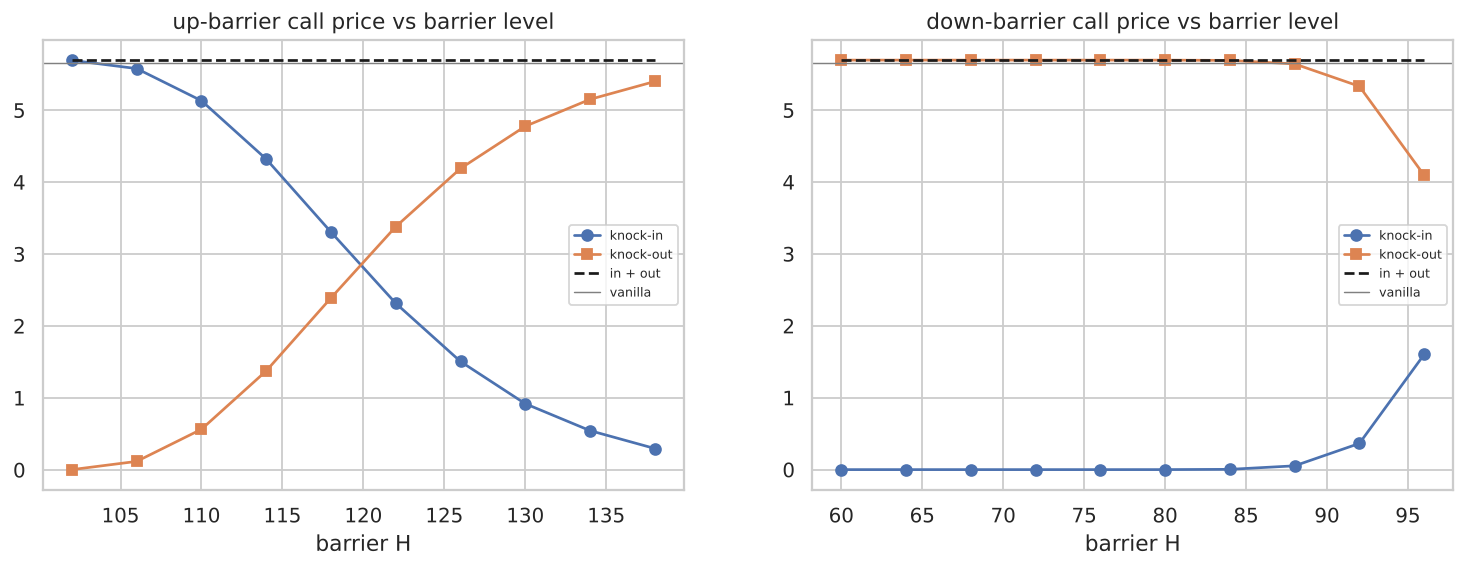

In [5]:
display(Image('../outputs/figures/05_barrier_price_vs_level.png'))

In [6]:
pd.read_csv('../outputs/tables/06_barrier_monitoring_frequency.csv').round(4)

,step_days,mc,se,continuous,bgk
0,4.00,1.2834,0.0026,0.9616,1.3679
1,2.00,1.2092,0.0025,0.9616,1.2519
2,1.00,1.1459,0.0025,0.9616,1.1679
3,0.50,1.0970,0.0024,0.9616,1.1078
4,0.25,1.0564,0.0024,0.9616,1.0650


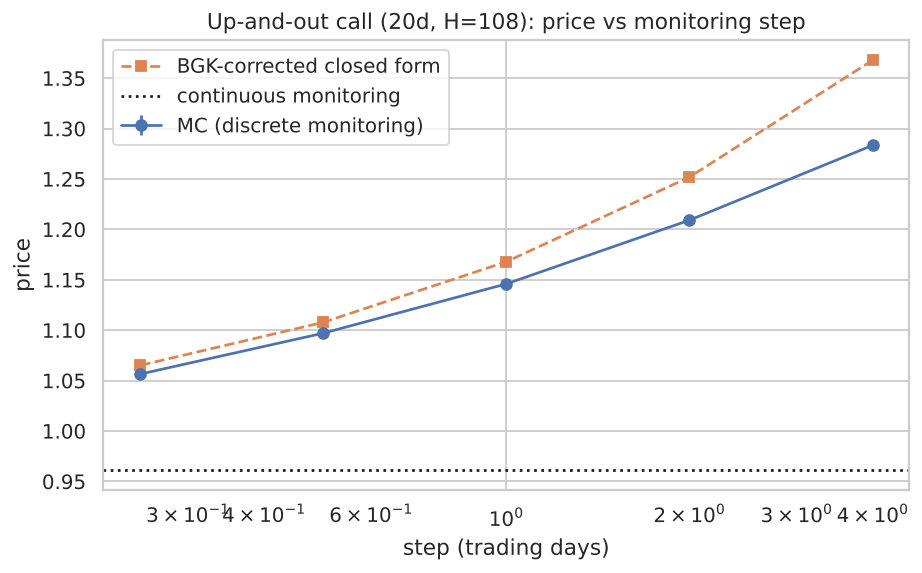

In [7]:
display(Image('../outputs/figures/06_barrier_monitoring_frequency.png'))

As the monitoring step shrinks the discrete price converges to the continuous one. The BGK shift works well for small steps and overstates for very coarse monitoring.

## 4. The 0.5-day vs 1-day step rule

In [8]:
t = pd.read_csv('../outputs/tables/07_time_step_rule.csv'); t[t.expiry_days.isin([25, 29, 30, 31])].round(4)

,expiry_days,steps,step_used,asian,asian_se,uo_call,uo_se
6,25,rule,0.5,1.5972,0.0000,0.9581,0.0028
7,25,1-day steps,1.0,1.6215,0.0000,1.0065,0.0029
8,25,0.5-day steps,0.5,1.5972,0.0000,0.9581,0.0028
9,29,rule,0.5,1.7267,0.0000,0.8595,0.0027
10,29,1-day steps,1.0,1.7493,0.0001,0.9153,0.0028
11,29,0.5-day steps,0.5,1.7267,0.0000,0.8595,0.0027
12,30,rule,1.0,1.7802,0.0001,0.8908,0.0028
13,30,1-day steps,1.0,1.7802,0.0001,0.8908,0.0028
14,30,0.5-day steps,0.5,1.7578,0.0001,0.8398,0.0027
15,31,rule,1.0,1.8105,0.0001,0.8698,0.0028


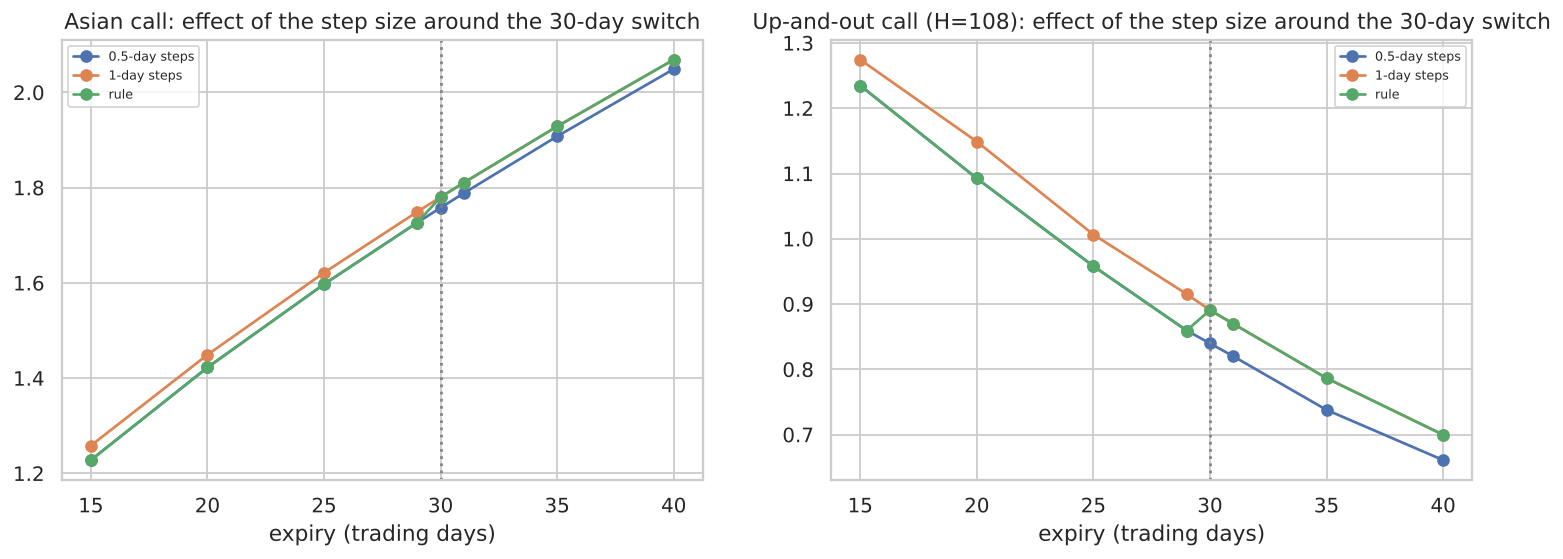

In [9]:
display(Image('../outputs/figures/07_time_step_rule.png'))

At 29 days, using half-day steps instead of daily steps lowers the up-and-out call price by about 6% and the Asian price by about 1%. At 30 days the rule switches to daily steps, which produces a small kink in price against expiry.

## 5. American options (Longstaff-Schwartz)

In [10]:
pd.read_csv('../outputs/tables/08_american_put.csv').round(3)

,expiry_days,S0,lsm,se,binomial,european,intrinsic,early_exercise_premium,lsm_minus_tree,in_sample_lsm
0,90,80,19.980,0.000,20.000,18.416,20.0,1.584,-0.020,19.980
1,90,90,10.391,0.012,10.387,9.749,10.0,0.638,0.004,10.382
2,90,100,4.030,0.009,4.051,3.891,0.0,0.161,-0.021,4.051
3,90,110,1.175,0.008,1.175,1.143,0.0,0.032,-0.001,1.177
4,90,120,0.256,0.004,0.257,0.252,0.0,0.005,-0.001,0.263
5,252,80,19.985,0.004,20.000,16.982,20.0,3.018,-0.015,19.986
6,252,90,11.476,0.015,11.493,10.214,10.0,1.279,-0.017,11.488
7,252,100,6.067,0.013,6.090,5.574,0.0,0.516,-0.023,6.073
8,252,110,2.980,0.014,2.987,2.786,0.0,0.201,-0.007,2.971
9,252,120,1.367,0.011,1.367,1.292,0.0,0.075,-0.001,1.357


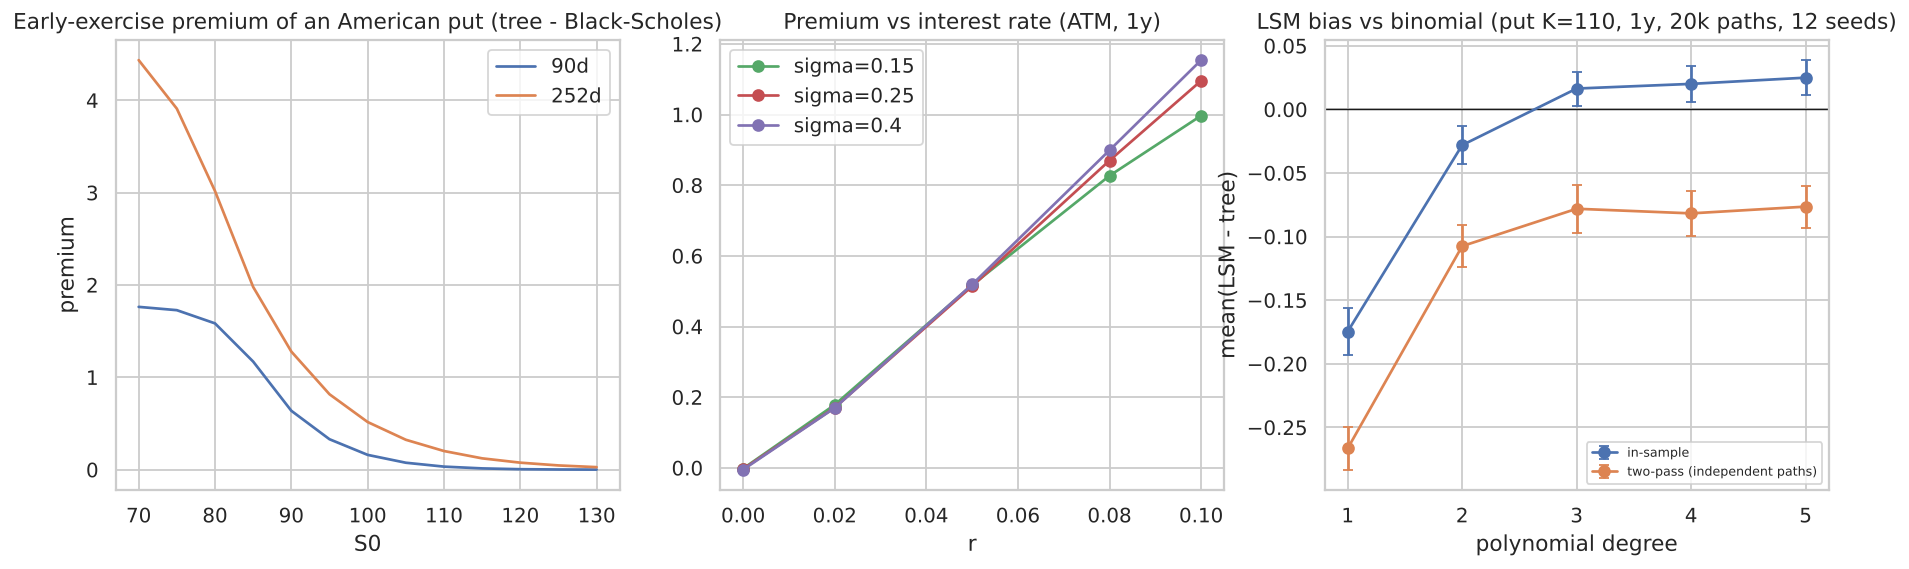

,degree,estimator,mean_error,se_of_mean,tree
0,1,two-pass (independent paths),-0.2665,0.0166,11.9732
1,1,in-sample,-0.1747,0.0186,11.9732
2,2,two-pass (independent paths),-0.1075,0.0163,11.9732
3,2,in-sample,-0.0281,0.0148,11.9732
4,3,two-pass (independent paths),-0.0781,0.0190,11.9732
5,3,in-sample,0.0164,0.0134,11.9732
6,4,two-pass (independent paths),-0.0817,0.0179,11.9732
7,4,in-sample,0.0200,0.0144,11.9732
8,5,two-pass (independent paths),-0.0764,0.0165,11.9732
9,5,in-sample,0.0249,0.0138,11.9732


In [11]:
display(Image('../outputs/figures/08_american_put_lsm.png')); pd.read_csv('../outputs/tables/09_lsm_basis_and_bias.csv').round(4)

LSM agrees with an independent 2,000-step tree within about 2 cents. The early-exercise premium rises with maturity and moneyness. A linear basis is too crude; degree >= 3 is enough. The two-pass estimator is a lower bound; averaged over seeds the in-sample estimator is close to unbiased here.

## 6. Greeks

In [12]:
pd.read_csv('../outputs/tables/10_greeks_european.csv').round(4)

,type,greek,mc,black_scholes,abs_error,rel_error
0,call,delta,0.5827,0.5828,-0.0001,-0.0002
1,call,gamma,0.0327,0.0327,0.0000,0.0014
2,call,vega,0.2331,0.2333,-0.0002,-0.0007
3,call,theta,-0.0364,-0.0364,-0.0001,-0.0016
4,call,rho,0.1880,0.1879,0.0000,0.0001
5,put,delta,-0.4173,-0.4172,-0.0001,-0.0002
6,put,gamma,0.0327,0.0327,0.0000,0.0014
7,put,vega,0.2332,0.2333,-0.0001,-0.0004
8,put,theta,-0.0169,-0.0169,-0.0001,-0.0039
9,put,rho,-0.1629,-0.1629,0.0000,0.0001


In [13]:
pd.read_csv('../outputs/tables/11_delta_bump_study.csv').round(5)

,rel_bump,common_random_numbers,rmse,bias
0,0.0005,True,0.00220,-0.00026
1,0.0005,False,0.75656,0.06318
2,0.0020,True,0.00222,-0.00025
3,0.0020,False,0.12981,0.01296
4,0.0100,True,0.00213,-0.00029
5,0.0100,False,0.02171,0.00475
6,0.0500,True,0.00409,-0.00355
7,0.0500,False,0.00710,-0.00349


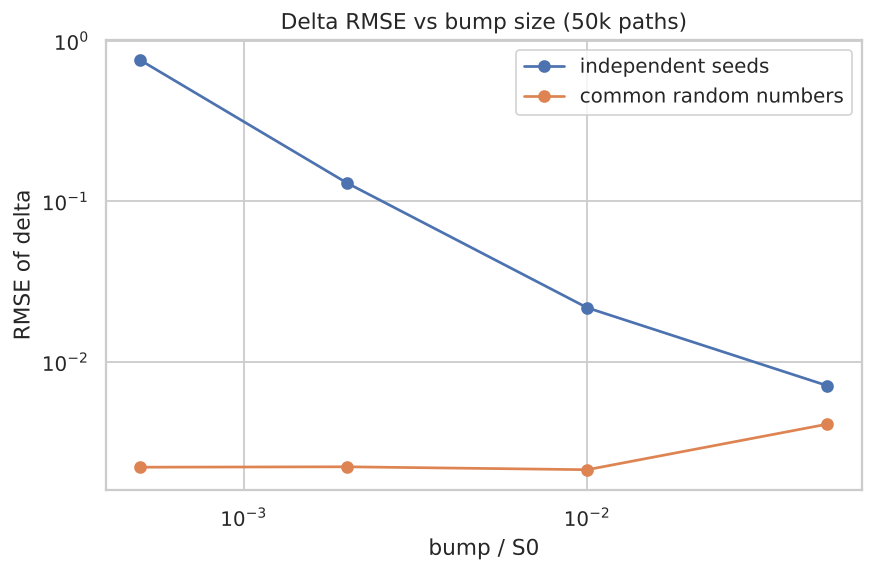

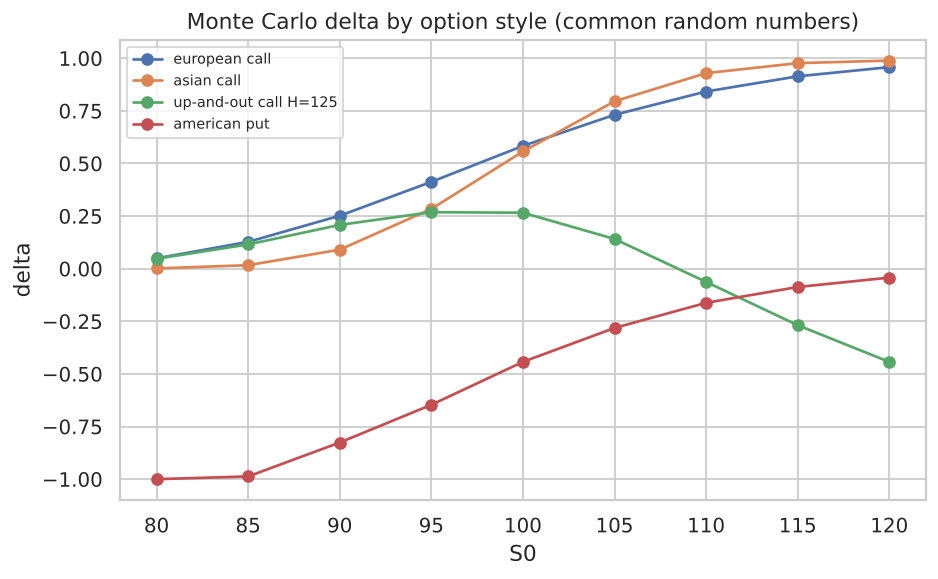

In [14]:
display(Image('../outputs/figures/09_delta_bump_and_crn.png')); display(Image('../outputs/figures/10_delta_by_style.png'))

With **common random numbers** the delta from a 0.05-1% bump has RMSE about 0.002; with independent seeds it explodes as the bump shrinks (0.76 at 0.05%). Delta shapes differ by style: the up-and-out call's delta collapses near the barrier.

## 7. Runtime

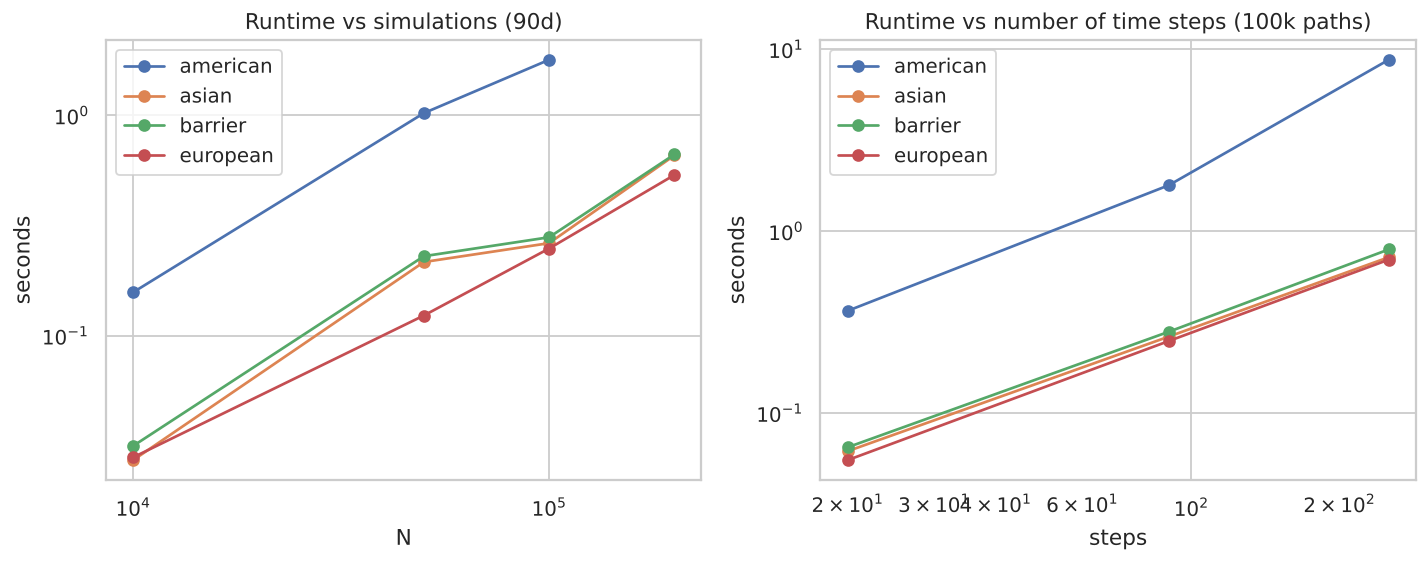

In [15]:
display(Image('../outputs/figures/11_runtime_scaling.png'))

Runtime grows linearly in paths and steps; the LSM is ~7x slower than the other styles because of two passes and regressions at every step.

## 8. Conclusion
The engine is validated across styles; discretisation (monitoring, step size) is as important as sampling error for path-dependent options.